## Model 3: Spaced Repetition

Now, we'd like to model how our memory strength over time if we utilize spaced repitition, meaning we reinforce the memory in discrete time steps.

We predict that the memory will stay above the retrieval threshold, meaning we're able to recall it, for a longer amount of time.

We are utilizing the same equations and assumptions as above, where the memory continues to decay exponentially between each memory reinforcement.

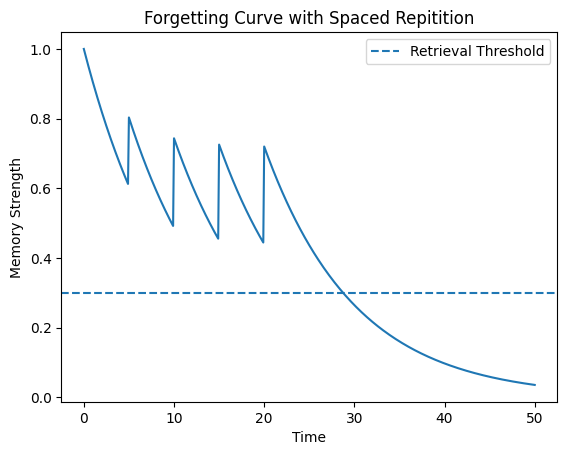

In [1]:
import numpy as np
import matplotlib.pyplot as plt

decay_rate = 0.1
retrieval_threshold = 0.3

learning_rate = 0.5
review_time_start = 5
review_time_end = 20
time_step = 5
review_time = review_time_start

time = np.linspace(0, 50, 501)
dt = time[1]-time[0]

memory_strength = np.zeros(len(time))
memory_strength[0] = 1.0

for i in range(1, len(time)):
    memory_strength[i] = memory_strength[i-1] * np.exp(-decay_rate * dt)

    if time[i-1] < review_time <= time[i]:
        memory_strength[i] = memory_strength[i] + learning_rate * (1 - memory_strength[i])
        
        if review_time < review_time_end:
            review_time += time_step

plt.plot(time, memory_strength)
plt.axhline(y=retrieval_threshold, linestyle='--', label='Retrieval Threshold')

plt.xlabel('Time')
plt.ylabel('Memory Strength')
plt.title('Forgetting Curve with Spaced Repitition')
plt.legend()

plt.show()


### Interpretation of Model 3

As seen by the graph above, spaced repetition allows for the memory strength to stay above the retrieval threshold for longer.

Next, we'll explore the question: What if successful reinforcement doesn't merely increase w, but also makes the memory decay more slowly afterward?